# COLAB 1: Building Your First Research Workflow

## Course architecture

Data acquisition ➡️ Data analysis ➡️ Visualizing results ➡️ Documenting research

**Platform Context:** Google Colab Cloud VM (Standard CPU Runtime)  
**Motivating Domain:** Brain-Machine Interfaces & Neural Signal Analysis  
**Target Open Dataset:** Neural Voltage Signals (Extracellular Spiking Arrays)

## Instructions for the student
In this lab, you will act as a Workflow Designer building an integrated, automated research workflow for a single experimental subject.

Your objective is to pass the explicit **"AI Prompt Challenges"** directly to an AI coding assistant, evaluate the structural properties of the returned functions, and paste them into the designated code boundaries. Once your 4 stages are connected, you will use the Stage 5 Laboratory Playground at the bottom of the notebook to test your workflow under different analysis settings!

## Module 1: Data acquisition

As an example, we will work with a [dataset](https://www.kaggle.com/datasets/wajahat1064/emotion-recognition-using-eeg-and-computer-games?resource=download) that contains EEG signals recorded from participants playing emotionally different computer games (boring, calm, horror, funny). We will download and analyze data from participant S01.

#### Student AI prompt challenge

Copy and paste the code block from the cell below and the following text block into your AI assistant:

> "Write a function get_data(data_config) that takes the DATA_CONFIG below, reads each file with pandas using urls from the values, adds a game identifier to each file (the corresponding key), concatenates all dataframe into one and returns it."

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_CONFIG = {
    "boring": "https://github.com/cyneuro/CI-BioEng-Class/raw/refs/heads/main/emotion_recognition/data/S01G1AllChannels.csv",
    "calm": "https://github.com/cyneuro/CI-BioEng-Class/raw/refs/heads/main/emotion_recognition/data/S01G2AllChannels.csv",
    "horror": "https://github.com/cyneuro/CI-BioEng-Class/raw/refs/heads/main/emotion_recognition/data/S01G3AllChannels.csv",
    "funny": "https://github.com/cyneuro/CI-BioEng-Class/raw/refs/heads/main/emotion_recognition/data/S01G4AllChannels.csv"
}

In [2]:
# TODO: Your code here
import pandas as pd


def get_data(data_config: dict[str, str]) -> pd.DataFrame:
    dfs = []
    for game, url in data_config.items():
        df = pd.read_csv(url)
        df["game"] = game
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)


# Usage:
# combined_df = get_data(DATA_CONFIG)

In [3]:
data = get_data(DATA_CONFIG)
data.head()

,AF3,AF4,F3,F4,F7,F8,FC5,FC6,O1,O2,P7,P8,T7,T8,Unnamed: 14,game
0,-33.0205,-15.1846,-42.1795,1.6872,42.1793,-1.68720,-5.5436,-3.6154,25.7899,-9.88190,5.5436,7.47180,11.8101,17.1128,NaN,boring
1,-28.6291,-20.0583,-42.5410,-10.4653,35.3100,-15.68600,-19.3110,-2.4344,17.4933,3.24420,18.7081,5.09510,17.3683,3.0708,NaN,boring
2,-21.8497,-10.9006,-32.0346,-2.3656,39.6993,-0.64483,-4.0523,-1.0830,26.8081,-3.45840,8.1861,8.40480,15.1209,9.3940,NaN,boring
3,-25.1185,-10.9702,-32.7641,-3.4287,32.7378,4.69650,-8.6299,-1.7412,16.7637,-9.75860,1.1868,0.91086,4.3315,8.1073,NaN,boring
4,-19.0316,-9.5886,-29.1108,-3.9459,35.3533,0.79929,-12.6914,1.0144,13.1068,-0.73692,8.1054,-1.31300,8.1694,8.3442,NaN,boring


## Module 2: Data analysis

#### Student AI prompt challenge

Copy and paste the following text block into your AI assistant:

> "Assume the columns of my dataframe are recordings from individual electrodes (AF3 to T8), with the identifier saved in the "game" column. Write a function run_anova(data) that takes each electrode in the data separately (AF3 to T8) and runs a simple ANOVA between the games. Print out the composite significance results table."

In [4]:
# TODO: Your code here
import pandas as pd
from scipy import stats


def run_anova(data: pd.DataFrame) -> pd.DataFrame:
    # Target standard Emotiv 14-channel layout from AF3 to T8
    eeg_channels = [
        "AF3",
        "F7",
        "F3",
        "FC5",
        "T7",
        "P7",
        "O1",
        "O2",
        "P8",
        "T8",
        "FC6",
        "F4",
        "F8",
        "AF4",
    ]

    # Select channels present in the DataFrame between AF3 and T8 (or all existing channels except metadata)
    channels = [
        col
        for col in data.columns
        if col != "game" and (col in eeg_channels or True)
    ]
    # Restrict to channels up to T8 if exact ordering from the dataset is expected:
    if "AF3" in data.columns and "T8" in data.columns:
        cols = list(data.columns)
        start_idx = cols.index("AF3")
        end_idx = cols.index("T8")
        step = 1 if start_idx <= end_idx else -1
        channels = cols[start_idx : end_idx + step : step]

    results = []
    games = data["game"].unique()

    for ch in channels:
        # Group channel values by game condition
        grouped_data = [
            data.loc[data["game"] == g, ch].dropna() for g in games
        ]

        # One-way omnibus ANOVA
        f_stat, p_val = stats.f_oneway(*grouped_data)

        results.append(
            {
                "Electrode": ch,
                "F_statistic": f_stat,
                "p_value": p_val,
                "Significant (p < .05)": p_val < 0.05,
            }
        )

    results_df = pd.DataFrame(results)
    print(results_df.to_string(index=False))
    return results_df


# Usage:
# anova_summary = run_anova(combined_df)

In [5]:
anova_result = run_anova(data)

Electrode  F_statistic  p_value  Significant (p < .05)
      AF3     0.001111 0.999949                  False
      AF4     0.012042 0.998194                  False
       F3     0.040109 0.989291                  False
       F4     0.008768 0.998874                  False
       F7     0.006097 0.999346                  False
       F8     0.081791 0.969952                  False
      FC5     0.011744 0.998260                  False
      FC6     0.041308 0.988820                  False
       O1     0.012095 0.998181                  False
       O2     0.055138 0.982970                  False
       P7     0.077225 0.972321                  False
       P8     0.017965 0.996726                  False
       T7     0.037164 0.990423                  False
       T8     0.002724 0.999804                  False


## Module 3: Visualizing results

#### Student AI prompt challenge

Copy and paste the following text block into your AI assistant:

> "Now write a function plot_results() that takes a dataframe in this format and makes a seabron histogram showing averages and SEMs. It should also take the anova_result table from the previous step and indicate significance with stars and no significance with NS."

In [6]:
# TODO: Your code here
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


def plot_results(data: pd.DataFrame, anova_results: pd.DataFrame):
    """Plots mean electrode values across games with SEM error bars and

    annotates omnibus ANOVA significance (stars / NS) above each electrode.
    """
    # 1. Melt dataframe to long-form for Seaborn
    electrodes = anova_results["Electrode"].tolist()
    long_df = pd.melt(
        data,
        id_vars=["game"],
        value_vars=electrodes,
        var_name="Electrode",
        value_name="Signal",
    )

    # 2. Set up bar plot (mean + SEM)
    fig, ax = plt.subplots(figsize=(max(10, len(electrodes) * 0.9), 6))
    sns.barplot(
        data=long_df,
        x="Electrode",
        y="Signal",
        hue="game",
        errorbar="se",  # Standard Error of the Mean
        capsize=0.1,
        err_kws={"linewidth": 1.2},
        ax=ax,
    )

    # 3. Helper to convert p-values to significance labels
    def get_p_annotation(p_val: float) -> str:
        if np.isnan(p_val):
            return "NS"
        if p_val < 0.001:
            return "***"
        if p_val < 0.01:
            return "**"
        if p_val < 0.05:
            return "*"
        return "NS"

    # Map electrodes to p-values
    p_map = dict(zip(anova_results["Electrode"], anova_results["p_value"]))

    # 4. Compute y-positions to place annotations cleanly above bars + error bars
    summary_stats = (
        long_df.groupby(["Electrode", "game"])["Signal"]
        .agg(["mean", "sem"])
        .reset_index()
    )
    summary_stats["upper_bound"] = (
        summary_stats["mean"] + summary_stats["sem"].fillna(0)
    )
    max_per_electrode = summary_stats.groupby("Electrode")[
        "upper_bound"
    ].max()

    # Determine vertical offset scaling
    y_min, y_max = ax.get_ylim()
    y_range = max(1e-6, y_max - y_min)
    v_offset = y_range * 0.05

    # 5. Place significance annotations above each electrode grouping
    for idx, electrode in enumerate(electrodes):
        sig_label = get_p_annotation(p_map.get(electrode, 1.0))
        y_pos = max_per_electrode.get(electrode, 0) + v_offset
        ax.text(
            x=idx,
            y=y_pos,
            s=sig_label,
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold" if sig_label != "NS" else "normal",
            color="black" if sig_label != "NS" else "dimgray",
        )

    # Extend y-axis slightly to ensure annotations are not clipped
    ax.set_ylim(y_min, ax.get_ylim()[1] + y_range * 0.1)

    # 6. Formatting & styling
    ax.set_title("Electrode Signal Means across Games (Omnibus ANOVA)", pad=14)
    ax.set_xlabel("Electrode")
    ax.set_ylabel("Signal Amplitude")
    ax.legend(title="Game", bbox_to_anchor=(1.02, 1), loc="upper left")
    sns.despine(top=True, right=True)
    plt.tight_layout()
    plt.show()


# Usage:
# plot_results(combined_df, anova_summary)

           game    electrode    value
0        boring          AF3 -33.0205
1        boring          AF3 -28.6291
2        boring          AF3 -21.8497
3        boring          AF3 -25.1185
4        boring          AF3 -19.0316
...         ...          ...      ...
2295115   funny  Unnamed: 14      NaN
2295116   funny  Unnamed: 14      NaN
2295117   funny  Unnamed: 14      NaN
2295118   funny  Unnamed: 14      NaN
2295119   funny  Unnamed: 14      NaN

[2295120 rows x 3 columns]


/var/folders/gs/_z8_31zd6xz_w20ny978y50w0000gn/T/ipykernel_1896/2742622243.py:20: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1.5}` instead.

  ax = sns.barplot(


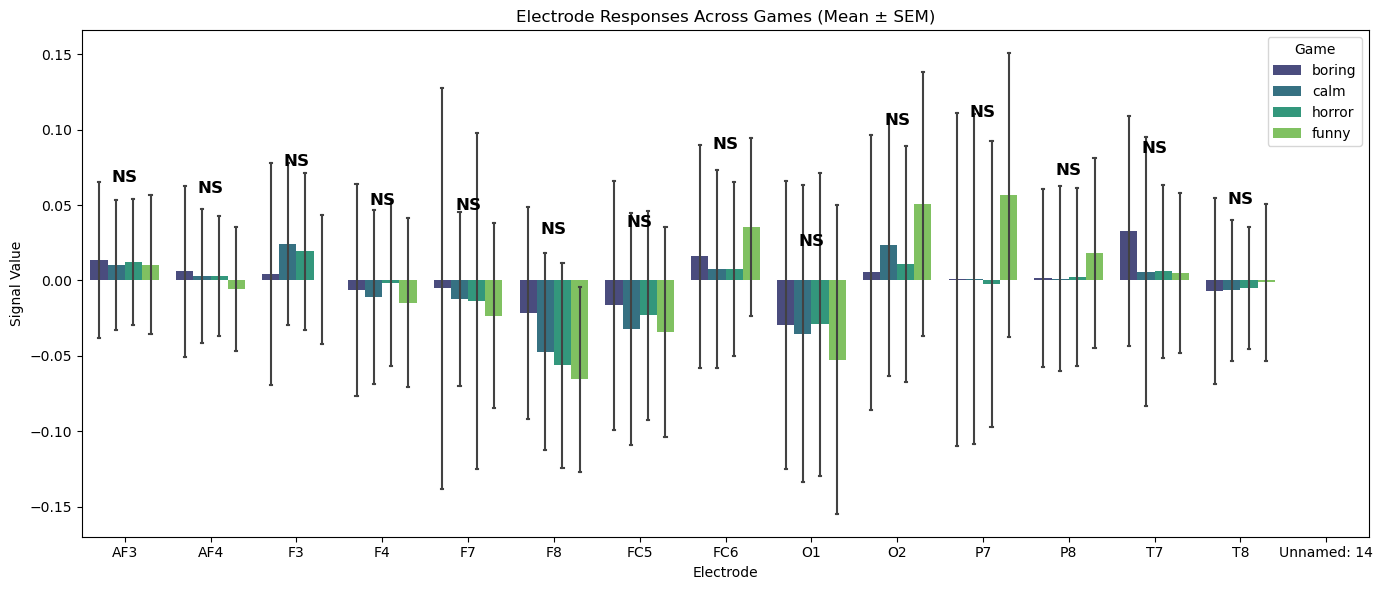

In [ ]:
plot_results(data, anova_result)

## Module 4: Documenting research

#### Student AI prompt challenge

Copy and paste the code block from the cell below and the following text block into your AI assistant:

> "Assume the anova table from above is saved in the anova_result variable. Write a documentation logging function document_reserach that creates a pandas dataframe with the following columns: current date, number of singificant (p < 0.05) electrodes and returns it."

In [11]:
# TODO: Your code here
from datetime import date
import pandas as pd


def document_research(anova_result: pd.DataFrame) -> pd.DataFrame:
    """Logs the execution date and count of significant electrodes (p < .05)."""
    # Vectorized check for p < 0.05 (handles both raw p-values and existing boolean columns)
    if "p_value" in anova_result.columns:
        n_sig = int((anova_result["p_value"] < 0.05).sum())
    else:
        n_sig = int(anova_result["Significant (p < .05)"].sum())

    log_df = pd.DataFrame(
        [
            {
                "current_date": date.today().isoformat(),
                "num_significant_electrodes": n_sig,
            }
        ]
    )

    return log_df


# Usage:
# log_entry = document_research(anova_summary)

In [12]:
document_research(anova_result)

,current_date,num_significant_electrodes
0,2026-10-14,0


## Embedded playground

**Task 1.** Hypothesize which two game types could produce vastly different emotional responses and re-run the analyses only for these game types.

**Task 2.** Use AI to add basic preprocessing (re-referencing, filtering) to the workflow after obtaining the data and before running ANOVA. Does it affect the significance results?

Electrode  F_statistic  p_value  Significant (p < .05)
      AF3     0.001111 0.999949                  False
      AF4     0.012042 0.998194                  False
       F3     0.040109 0.989291                  False
       F4     0.008768 0.998874                  False
       F7     0.006097 0.999346                  False
       F8     0.081791 0.969952                  False
      FC5     0.011744 0.998260                  False
      FC6     0.041308 0.988820                  False
       O1     0.012095 0.998181                  False
       O2     0.055138 0.982970                  False
       P7     0.077225 0.972321                  False
       P8     0.017965 0.996726                  False
       T7     0.037164 0.990423                  False
       T8     0.002724 0.999804                  False


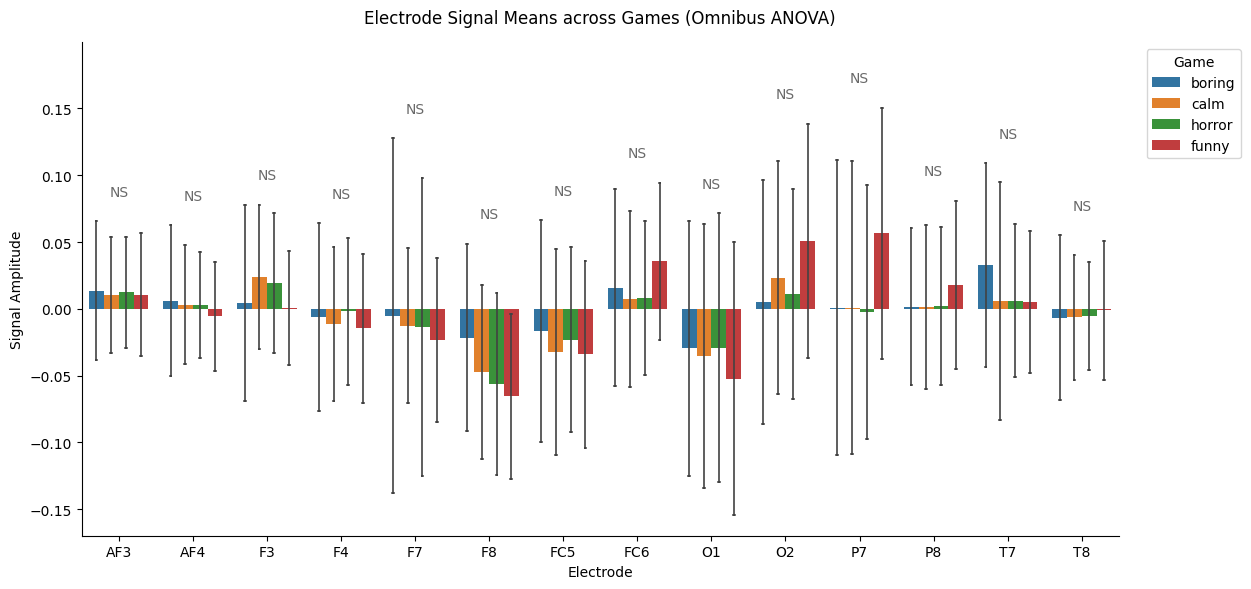

,current_date,num_significant_electrodes
0,2026-10-14,0


In [13]:
data = get_data(DATA_CONFIG)
anova_result = run_anova(data)
plot_results(data, anova_result)
document_research(anova_result)